EMPLOYEE SKILL MATRIX
employee  Python  SQL  Power BI  Project Management
     E01       4    3         2                   2
     E02       2    4         4                   3
     E03       1    2         3                   4
     E04       3    3         1                   2
     E05       2    1         2                   3
     E06       4    2         3                   2
     E07       1    4         2                   3
     E08       3    3         4                   4

PROJECT SKILL REQUIREMENTS
             skill  required_people_at_level_3
            Python                           4
               SQL                           4
          Power BI                           3
Project Management                           3

AVAILABLE SKILL SUPPLY
             skill  available_people_at_level_3
            Python                            4
               SQL                            5
          Power BI                            4
Project Management             

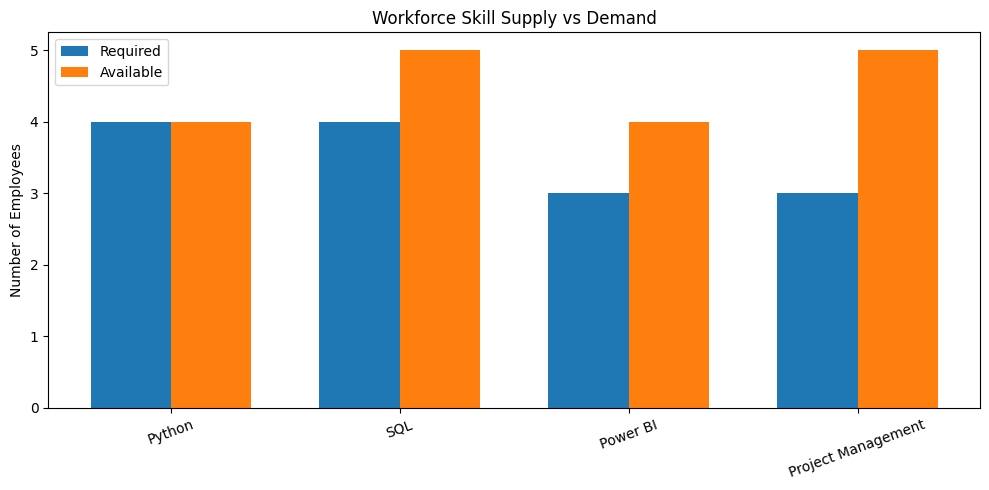


POTENTIAL TRAINING OPPORTUNITIES

Skill: Python
Employees below level 3:
employee  Python
     E02       2
     E03       1
     E05       2
     E07       1

Skill: SQL
Employees below level 3:
employee  SQL
     E03    2
     E05    1
     E06    2

Skill: Power BI
Employees below level 3:
employee  Power BI
     E01         2
     E04         1
     E05         2
     E07         2

Skill: Project Management
Employees below level 3:
employee  Project Management
     E01                   2
     E04                   2
     E06                   2

WORKFORCE RECOMMENDATIONS
Python: target skill supply is met. Validate employee availability and project timing.
SQL: target skill supply is met. Validate employee availability and project timing.
Power BI: target skill supply is met. Validate employee availability and project timing.
Project Management: target skill supply is met. Validate employee availability and project timing.

PROJECT SUMMARY
1. Mapped employee skill levels.
2. Comp

In [1]:

# PROJECT 6: WORKFORCE CAPACITY & SKILL GAP ANALYSIS

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# STEP 2: CREATE EMPLOYEE SKILL DATA

employees = pd.DataFrame([
    {"employee": "E01", "Python": 4, "SQL": 3, "Power BI": 2,
     "Project Management": 2},
    {"employee": "E02", "Python": 2, "SQL": 4, "Power BI": 4,
     "Project Management": 3},
    {"employee": "E03", "Python": 1, "SQL": 2, "Power BI": 3,
     "Project Management": 4},
    {"employee": "E04", "Python": 3, "SQL": 3, "Power BI": 1,
     "Project Management": 2},
    {"employee": "E05", "Python": 2, "SQL": 1, "Power BI": 2,
     "Project Management": 3},
    {"employee": "E06", "Python": 4, "SQL": 2, "Power BI": 3,
     "Project Management": 2},
    {"employee": "E07", "Python": 1, "SQL": 4, "Power BI": 2,
     "Project Management": 3},
    {"employee": "E08", "Python": 3, "SQL": 3, "Power BI": 4,
     "Project Management": 4}
])

print("EMPLOYEE SKILL MATRIX")
print(employees.to_string(index=False))


# STEP 3: DEFINE PROJECT SKILL REQUIREMENTS

requirements = pd.DataFrame({
    "skill": [
        "Python", "SQL", "Power BI", "Project Management"
    ],
    "required_people_at_level_3": [4, 4, 3, 3]
})

print("\nPROJECT SKILL REQUIREMENTS")
print(requirements.to_string(index=False))


# STEP 4: CALCULATE AVAILABLE SKILLS

skill_columns = [
    "Python", "SQL", "Power BI", "Project Management"
]

available = []

for skill in skill_columns:
    count = (employees[skill] >= 3).sum()
    available.append({
        "skill": skill,
        "available_people_at_level_3": int(count)
    })

supply = pd.DataFrame(available)

print("\nAVAILABLE SKILL SUPPLY")
print(supply.to_string(index=False))


# STEP 5: IDENTIFY SKILL GAPS

gap_analysis = requirements.merge(
    supply,
    on="skill"
)

gap_analysis["skill_gap"] = (
    gap_analysis["required_people_at_level_3"]
    - gap_analysis["available_people_at_level_3"]
)

gap_analysis["recommendation"] = np.where(
    gap_analysis["skill_gap"] > 0,
    "Train employees or consider hiring",
    "Current skill supply meets target"
)

print("\nSKILL GAP ANALYSIS")
print(gap_analysis.to_string(index=False))


# STEP 6: VISUALIZE SKILL REQUIREMENTS VS SUPPLY

x = np.arange(len(gap_analysis))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    gap_analysis["required_people_at_level_3"],
    width,
    label="Required"
)

plt.bar(
    x + width / 2,
    gap_analysis["available_people_at_level_3"],
    width,
    label="Available"
)

plt.xticks(
    x,
    gap_analysis["skill"],
    rotation=20
)

plt.ylabel("Number of Employees")
plt.title("Workforce Skill Supply vs Demand")
plt.legend()
plt.tight_layout()
plt.show()


# STEP 7: IDENTIFY EMPLOYEES FOR DEVELOPMENT

print("\nPOTENTIAL TRAINING OPPORTUNITIES")

for skill in skill_columns:
    candidates = employees.loc[
        (employees[skill] < 3),
        ["employee", skill]
    ]

    print(f"\nSkill: {skill}")
    print("Employees below level 3:")

    if len(candidates) == 0:
        print("None")
    else:
        print(candidates.to_string(index=False))


# STEP 8: RECOMMEND WORKFORCE ACTIONS

print("\nWORKFORCE RECOMMENDATIONS")

for _, row in gap_analysis.iterrows():
    skill = row["skill"]
    gap = row["skill_gap"]

    if gap > 0:
        print(
            f"{skill}: shortage of {gap} employee(s) "
            "at the target skill level. Review training, "
            "internal allocation, or hiring."
        )
    else:
        print(
            f"{skill}: target skill supply is met. "
            "Validate employee availability and project timing."
        )


# STEP 9: SUMMARY

print("\nPROJECT SUMMARY")
print("1. Mapped employee skill levels.")
print("2. Compared skill supply with project requirements.")
print("3. Identified potential skill shortages.")
print("4. Listed training opportunities.")
print("5. Generated workforce planning recommendations.")

print("\nPROJECT 6 COMPLETED SUCCESSFULLY")
print("Note: The employee and requirement data are illustrative.")
